<a href="https://colab.research.google.com/github/GilangAngga12/Pemrosesan-teks-praktik/blob/main/22oktoberBOW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Preprocessing Teks

## Library

In [3]:
# %pip install pandas nltk Sastrawi wordcloud matplotlib

In [4]:
 %pip install polars nltk Sastrawi

In [5]:
import re
import html
import polars as pl
import nltk
import numpy as np
# import spacy
import unicodedata
from functools import lru_cache
from collections import Counter
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
# import pandas as pd

from nltk.corpus import stopwords
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [7]:
nltk.download("stopwords")

# Model spaCy untuk bahasa Indonesia
# spacy.cli.download("xx_ent_wiki_sm")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [8]:
ADDITIONAL_STOPWORDS = {
    'di',
    'dan',
    'yang',
    'ini',
    'dari',
    'itu',
    'untuk',
    'dengan',
    'ke',
    'ada',
    'juga',
    'tapi',
    'sama',
    'kita',
    'masih',
    'tidak',
    'pada',
    'mereka',
    'setelah',
    'dalam',
    'saat',
    'ya',
    'lebih',
    'karena',
    'bukan',
    'lagi',
    'akan',
    'dia',
    'buat',
    'sudah',
    'kalau',
    'harus',
    'satu',
    'saya',
    'kami',
    'para',
    'baru',
    'atau',
    'atas',
    'sebagai',
    'cuma',
    'tersebut',
    'mau',
    'adalah',
    'punya',
    'nya',
    'semua',
    'bersama',
    'terus',
    'apa',
    'oleh',
    'secara',
    'hingga',
    'namun',
    'tak',
    'selalu',
    'lain',
    'pun',
    'hal',
    'malah',
    'sendiri',
    'ketika',
    'saja',
    'bakal',
    'padahal',
    'semoga',
    'sini',
    'lalu',
    'beberapa',
    'mana',
    'sebelum',
    'jelas',
    'telah',
    'mulai',
    'bahkan',
    'seluruh',
    'sekaligus',
    'kenapa',
    'sejak',
    'lihat',
    'sempat',
    'kata',
    'awal',
    'lah',
    'pasti',
    'penuh',
    'nanti',
    'the',
    'to',
    'in',
    'and',
    'out',
    'you',
    'full',
    'gt',
    'amp',
    'si',
}

In [9]:
STOPWORDS = ADDITIONAL_STOPWORDS

## Helper Fungsion

In [10]:
def to_list(v):
    """map_elements memberi pl.Series untuk kolom list -> ubah ke list Python."""
    if v is None: return []
    if isinstance(v, pl.Series): return v.to_list()
    return list(v)

def _apply_str(df, col, out, fn):
    return df.with_columns(pl.col(col).map_elements(fn, return_dtype=pl.Utf8).alias(out))

def _apply_list(df, col, out, fn):
    return df.with_columns(
        pl.col(col).map_elements(lambda v: fn(to_list(v)), return_dtype=pl.List(pl.Utf8)).alias(out))

## Dataset

In [11]:
df = pl.read_csv("/content/sample_data/dataset_timnas_part_3.csv")

In [12]:
df

author/automatedBy,author/canDm,author/canMediaTag,author/coverPicture,author/createdAt,author/description,author/fastFollowersCount,author/favouritesCount,author/followers,author/following,author/hasCustomTimelines,author/id,author/isAutomated,author/isBlueVerified,author/isTranslator,author/isVerified,author/location,author/mediaCount,author/name,author/pinnedTweetIds/0,author/possiblySensitive,author/profilePicture,author/profile_bio/description,author/profile_bio/entities/description/hashtags/0/text,author/profile_bio/entities/description/hashtags/1/text,author/profile_bio/entities/description/hashtags/2/text,author/profile_bio/entities/description/hashtags/3/text,author/profile_bio/entities/description/hashtags/4/text,author/profile_bio/entities/description/hashtags/5/text,author/profile_bio/entities/description/hashtags/6/text,author/profile_bio/entities/description/hashtags/7/text,author/profile_bio/entities/description/urls/0/display_url,author/profile_bio/entities/description/urls/0/expanded_url,author/profile_bio/entities/description/urls/0/url,author/profile_bio/entities/description/urls/1/display_url,author/profile_bio/entities/description/urls/1/expanded_url,author/profile_bio/entities/description/urls/1/url,…,quoted_tweet_results/result/tweet/legacy/quote_count,quoted_tweet_results/result/tweet/legacy/quoted_status_id_str,quoted_tweet_results/result/tweet/legacy/quoted_status_permalink/display,quoted_tweet_results/result/tweet/legacy/quoted_status_permalink/expanded,quoted_tweet_results/result/tweet/legacy/quoted_status_permalink/url,quoted_tweet_results/result/tweet/legacy/reply_count,quoted_tweet_results/result/tweet/legacy/retweet_count,quoted_tweet_results/result/tweet/legacy/retweeted,quoted_tweet_results/result/tweet/legacy/user_id_str,quoted_tweet_results/result/tweet/note_tweet/is_expandable,quoted_tweet_results/result/tweet/note_tweet/note_tweet_results/rest_id,quoted_tweet_results/result/tweet/quoted_tweet_results/rest_id,quoted_tweet_results/result/tweet/quoted_tweet_results/result/__typename,quoted_tweet_results/result/tweet/quoted_tweet_results/result/is_translatable,quoted_tweet_results/result/tweet/quoted_tweet_results/result/rest_id,quoted_tweet_results/result/tweet/rest_id,quoted_tweet_results/result/tweet/unmention_data/id,quoted_tweet_results/result/tweet/view_count_info/count,quoted_tweet_results/result/tweet/view_count_info/state,quoted_tweet_results/result/unmention_data/id,quoted_tweet_results/result/view_count_info/count,quoted_tweet_results/result/view_count_info/state,replyCount,reply_to_user_results,reply_to_user_results/rest_id,reply_to_user_results/result/__typename,reply_to_user_results/result/core/screen_name,reply_to_user_results/result/rest_id,retweetCount,retweeted_tweet,searchTermIndex,source,text,twitterUrl,type,url,viewCount
str,bool,bool,str,str,str,i64,i64,i64,i64,bool,i64,bool,bool,bool,bool,str,i64,str,f64,bool,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,i64,str,i64,str,str,str,str,str,i64
null,false,true,"""https://pbs.twimg.com/profile_…","""Tue Apr 07 03:09:26 +0000 2026""",null,0,9712,793,608,true,2041352553317761024,false,true,false,false,"""Jakarta, Indonesia""",388,"""Dunia Dalam Berita (Terkini)🌍""",2.1081e18,false,"""https://pbs.twimg.com/profile_…","""Berita Terkini, Viral, Ilmu Pe…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,0,null,null,null,null,null,0,null,2,null,"""@Panathinatikos Akh ga juga ma…","""https://twitter.com/DalamDunia…","""tweet""","""https://x.com/DalamDunia888/st…",139
null,false,true,"""https://pbs.twimg.com/profile_…","""Sat Nov 26 15:16:05 +0000 2011""",null,0,27787,19208,1988,true,421916203,false,false,false,false,"""Ambon-Maluku""",6131,"""DMS 102,7 FM Ambon""",null,false

In [13]:
df = df.select("text")
df

text
str
"""@Panathinatikos Akh ga juga ma…"
"""John Herdman Sebut Juara ASEAN…"
"""Pelatih Timnas Indonesia, John…"
"""Untuk John Herdman, titel kamp…"
"""John Herdman Sebut Gelar FIFA …"
…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …"
"""Ternyata mereka masih tetap se…"
"""@MatahariMahard2 @panditfootba…"


In [14]:
df.dtypes

[String]

## Noise Removal

Noise Removal digunakan untuk membersihkan atau menghapus elemen yang biasanya tidak dibutuhkan dalam analisis teks, seperti HTML, URL, alamat email, mention, karakter kontrol, dan spasi berlebih yang tidak relevan dan tidak memiliki nilai informasi untuk analisis teks.

Contoh yang dibersihkan: Tanda baca, emoji, tag HTML, URL, karakter khusus (seperti @, #, $), dan spasi berlebih (whitespace).

### Code

In [15]:
import re

def remove_emoji(text):
    if text is None:
        return ""

    emoji_pattern = re.compile(
        '['
        '\U0001f600-\U0001f64f'  # Emoticons
        '\U0001f300-\U0001f5ff'  # Symbols & Pictographs
        '\U0001f680-\U0001f6ff'  # Transport & Map Symbols
        '\U0001f1e0-\U0001f1ff'  # Flags
        '\U00002702-\U000027b0'  # Dingbats
        '\U00002600-\U000026ff'  # Miscellaneous Symbols
        '\U0001f900-\U0001f9ff'  # Supplemental Symbols
        '\U0001fa70-\U0001faff'  # Symbols Extended-A
        '\U0000fe00-\U0000fe0f'  # Variation Selectors
        '\U0001f3fb-\U0001f3ff'  # Skin Tone Modifiers
        '\U00010000-\U0010FFFF'  # Seluruh emoji, bendera, & pictograph
      '\u2600-\u26FF'  # Simbol kamera (📸, 🎥), bola (⚽), dll
      '\u2700-\u27BF'  # Dingbats
      '\u2300-\u23FF'  # Simbol teknikal
      '\u2B00-\u2BFF'  # Panah & simbol tambahan
      '\u200D'  # Zero Width Joiner
      '\uFE00-\uFE0F'
        ']+',
        flags=re.UNICODE,
    )

    # Hapus emoji dan rapikan spasi ganda
    cleaned_text = emoji_pattern.sub('', str(text))
    return re.sub(r' +', ' ', cleaned_text).strip()

In [16]:
# def noise_removal(df, text_col, output_col="text_clean"):
#     def clean(text):
#         if text is None: return ""
#         text = html.unescape(str(text)) # Ubah entity dari HTML
#         text = re.sub(r"<[^>]+>", " ", text) # Menghapus Tags HTML
#         text = re.sub(r"https?://\S+|www\.\S+|\b\w+\.(?:co|com|id)/\S+", " ", text) # Hapus URL
#         text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", " ", text) # Alamar email
#         text = re.sub(r"(?<!\w)@\w+", " ", text) # Hapus mentions
#         text = re.sub(r"^\s*RT\b", " ", text) # Hapus RT
#         # hashtag: buang '#', pisahkan CamelCase
#         text = re.sub(r"#(\w+)", lambda m: " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", m.group(1)) + " ", text)
#         text = EMOJI.sub(" ", text) # Emoji
#         text = re.sub(r"[\x00-\x1f\x7f]", " ", text) #ASCI
#         return re.sub(r"\s+", " ", text).strip()
#     return _apply_str(df, text_col, output_col, clean)

# ROMAN = re.compile(r"^m{0,3}(cm|cd|d?c{0,3})(xc|xl|l?x{0,3})(ix|iv|v?i{0,3})$")
# def _collapse(m):
#     w = m.group(0)
#     if ROMAN.match(w) or w == "www":      # III, XXX, www jangan diubah
#         return w
#     return re.sub(r"(\w)\1{2,}", r"\1", w)

### Code 2

In [17]:
DOMAIN = re.compile(r"\b[\w-]+(?:\.[\w-]+)*\.(?:com|co\.id|go\.id|or\.id|id|net|org|my|tv|news|info)\b(?:/\S*)?", re.I)
ROMAN = re.compile(r"^m{0,3}(cm|cd|d?c{0,3})(xc|xl|l?x{0,3})(ix|iv|v?i{0,3})$")

In [18]:
def noise_removal(df, text_col, output_col="text_clean"):
    def clean(text):
        if text is None: return ""
        text = html.unescape(str(text))
        text = re.sub(r"<[^>]+>", " ", text)
        text = re.sub(r"https?://\S+|www\.\S+", " ", text)
        text = DOMAIN.sub(" ", text)                                             # suaramerdeka.com/..., domain tanpa http
        text = re.sub(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", " ", text)
        text = re.sub(r"(?<!\w)@\w+", " ", text)
        text = re.sub(r"^\s*RT\b", " ", text)
        text = re.sub(r"\b\d{4}-\d{2}-\d{2}t?[\d:.]*\b", " ", text, flags=re.I)  # 2026-10-08T13:43
        text = re.sub(r"\b\d{8,}\b", " ", text)                                  # ID panjang
        text = re.sub(r"\b(?:pukul|jam)\s?\d{1,2}[.:]\d{2}(?:\s?[-–]\s?\d{1,2}[.:]\d{2})?(?:\s?(?:wib|wita|wit))?", " ", text, flags=re.I)
        text = re.sub(r"\b\d{1,2}[.:]\d{2}(?:\s?[-–]\s?\d{1,2}[.:]\d{2})?\s?(?:wib|wita|wit|am|pm)\b", " ", text, flags=re.I)
        text = re.sub(r"\b\d{1,2}:\d{2}\b", " ", text)                           # 13:43
        # hashtag: buang '#', pisahkan CamelCase (#RockyGerung -> Rocky Gerung)
        text = re.sub(r"#(\w+)", lambda m: " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", m.group(1)) + " ", text)
        text = EMOJI.sub(" ", text)
        text = re.sub(r"[\x00-\x1f\x7f]", " ", text)
        return re.sub(r"\s+", " ", text).strip()
    return _apply_str(df, text_col, output_col, clean)

In [19]:
import re

# Define the missing EMOJI regex pattern
EMOJI = re.compile(
    '['
    '\U0001f600-\U0001f64f'
    '\U0001f300-\U0001f5ff'
    '\U0001f680-\U0001f6ff'
    '\U0001f1e0-\U0001f1ff'
    '\U00002702-\U000027b0'
    '\U00002600-\U000026ff'
    '\U0001f900-\U0001f9ff'
    '\U0001fa70-\U0001faff'
    '\u2600-\u26FF'
    '\u2700-\u27BF'
    ']+',
    flags=re.UNICODE
)

df_noise = noise_removal(
    df, text_col="text"
)

In [20]:
df_noise

text,text_clean
str,str
"""@Panathinatikos Akh ga juga ma…","""Akh ga juga masih ada waktu bu…"
"""John Herdman Sebut Juara ASEAN…","""John Herdman Sebut Juara ASEAN…"
"""Pelatih Timnas Indonesia, John…","""Pelatih Timnas Indonesia, John…"
"""Untuk John Herdman, titel kamp…","""Untuk John Herdman, titel kamp…"
"""John Herdman Sebut Gelar FIFA …","""John Herdman Sebut Gelar FIFA …"
…,…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …","""BRI SUPER LEAGUE IS BACK ️ Set…"
"""Ternyata mereka masih tetap se…","""Ternyata mereka masih tetap se…"
"""@MatahariMahard2 @panditfootba…","""Mau mayoritas homegrown, diasp…"


In [21]:
print(type(df))


<class 'polars.dataframe.frame.DataFrame'>


## Normalisasi Teks

Normalisasi teks adalah proses menyeragamkan format teks, terutama huruf kapital, Unicode, dan spasi agar memiliki struktur linguistik yang seragam, terutama untuk teks tidak formal, bahasa gaul, singkatan, atau typo (typhographical errors).

Contoh: Mengubah kata "bgt" menjadi "banget", "udh" menjadi "sudah", atau menstandarisasi penulisan angka dan simbol mata uang.

### Code

In [22]:
SLANG = {
    "yg": "yang",
    "dg": "dengan",
    "dgn": "dengan",
    "utk": "untuk",
    "krn": "karena",
    "karna": "karena",
    "tdk": "tidak",
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "gk": "tidak",
    "enggak": "tidak",
    "ngga": "tidak",
    "bkn": "bukan",
    "bkan": "bukan",
    "sdh": "sudah",
    "udh": "sudah",
    "udah": "sudah",
    "blm": "belum",
    "jg": "juga",
    "jga": "juga",
    "sm": "sama",
    "sma": "sama",
    "klo": "kalau",
    "kalo": "kalau",
    "klu": "kalau",
    "kl": "kalau",
    "trus": "terus",
    "tp": "tapi",
    "tpi": "tapi",
    "aja": "saja",
    "bgt": "banget",
    "emg": "memang",
    "emang": "memang",
    "org": "orang",
    "ornag": "orang",
    "gw": "saya",
    "gue": "saya",
    "gua": "saya",
    "lu": "kamu",
    "loe": "kamu",
    "dr": "dari",
    "dlm": "dalam",
    "pd": "pada",
    "sbg": "sebagai",
    "spt": "seperti",
    "mknya": "makanya",
    "pkiran": "pikiran",
    "stlah": "setelah",
    "mnjbat": "menjabat",
    "ko": "kok",
    "mentri": "menteri",
    "thn": "tahun",
    "thun": "tahun",
    "nglantik": "melantik",
    "latarbelakang": "latar belakang",
    "ehh": "eh",
    "wajarlah": "wajar lah",
    "rg": "rocky gerung",
    "indo": "indonesia",
    "kayak": "seperti",
    "bikin": "membuat",
    "pake": "pakai",
    "pke": "pakai",
    "liat": "lihat",
    "ngeliat": "melihat",
    "sampe": "sampai",
    "smpe": "sampai",
    "gini": "begini",
    "gitu": "begitu",
    "gtu": "begitu",
    "gimana": "bagaimana",
    "gmn": "bagaimana",
    "biar": "agar",
    "tau": "tahu",
    "ngasih": "memberi",
    "dapet": "dapat",
    "ngomong": "bicara",
    "skrg": "sekarang",
    "ama": "sama",
    "inget": "ingat",
    "mikir": "berpikir",
    "lg": "lagi",
    "lgi": "lagi",
    "msh": "masih",
    "knp": "kenapa",
    "ngomongin": "membicarakan",
    "nemu": "menemukan",
    "kmrn": "kemarin",
    "kmren": "kemarin",
    "sblm": "sebelum",
    "stlh": "setelah",
    "prnh": "pernah",
    "blg": "bilang",
    "sdgkan": "sedangkan",
    "bgs": "bagus",
    "bbrp": "beberapa",
    "timnas": "tim nasional",
    "sty": "shin tae yong",
    "gbk": "gelora bung karno",
    "sugbk": "stadion utama gelora bung karno",
    "wni": "warga negara indonesia",
    "pssi": "persatuan sepakbola seluruh indonesia",
    "coach": "pelatih",
}

In [23]:
# def text_normalization(df, text_col, output_col="text_normalized", slang=SLANG):
#     def norm(text):
#         if not text: return ""
#         text = unicodedata.normalize("NFKC", text).lower()
#         text = re.sub(r"[“”„‟]", '"', text)
#         text = re.sub(r"[‘’‚‛]", "'", text)
#         text = re.sub(r"[—–]", " - ", text)
#         text = re.sub(r"\b\w*(\w)\1{2,}\w*\b", _collapse, text)       # mantaaap -> mantap (angka Romawi dikecualikan)
#         text = re.sub(r"\brp\s?(\d)", r"rp \1", text)                # rp76 -> rp 76
#         text = re.sub(r"\b([a-z]+)2\b", r"\1-\1", text)             # tiba2 -> tiba-tiba
#         text = re.sub(r"\b[a-z0-9]+\b", lambda m: slang.get(m.group(0), m.group(0)), text)
#         return re.sub(r"\s+", " ", text).strip()
#     return _apply_str(df, text_col, output_col, norm)

### Code 2

In [24]:
SLANG = {
    "yg": "yang", "dg": "dengan", "dgn": "dengan", "utk": "untuk", "krn": "karena",
    "karna": "karena", "tdk": "tidak", "gak": "tidak", "ga": "tidak", "nggak": "tidak",
    "gk": "tidak", "enggak": "tidak", "ngga": "tidak", "bkn": "bukan", "bkan": "bukan",
    "sdh": "sudah", "udh": "sudah", "udah": "sudah", "blm": "belum", "jg": "juga",
    "jga": "juga", "sm": "sama", "sma": "sama", "klo": "kalau", "kalo": "kalau",
    "klu": "kalau", "trus": "terus", "tp": "tapi", "tpi": "tapi", "aja": "saja",
    "bgt": "banget", "emg": "memang", "emang": "memang", "org": "orang", "ornag": "orang",
    "gw": "saya", "gue": "saya", "gua": "saya", "lu": "kamu", "loe": "kamu",
    "dr": "dari", "dlm": "dalam", "pd": "pada", "sbg": "sebagai", "spt": "seperti",
    "mknya": "makanya", "pkiran": "pikiran", "stlah": "setelah", "mnjbat": "menjabat",
    "ko": "kok", "mentri": "menteri", "thn": "tahun", "nglantik": "melantik",
    "latarbelakang": "latar belakang", "ehh": "eh", "wajarlah": "wajar lah",
    "ngoceh": "mengoceh", "ngalir": "mengalir", "ngantongin": "mengantongi",
    "rg": "rocky gerung",           # istilah domain
}

In [25]:
NOMINAL = re.compile(r"(?:\brp\.?\s?)?\b(\d+(?:[.,]\d+)?)\s?(jt|juta|jutaan|rb|ribu|ribuan|miliar|milyar|triliun)\b")

In [26]:
ROOT = set(StemmerFactory().get_words())                       # kata dasar Sastrawi

In [27]:
SATUAN = {"jt": "juta", "juta": "juta", "jutaan": "juta", "rb": "ribu", "ribu": "ribu",
          "ribuan": "ribu", "miliar": "miliar", "milyar": "miliar", "triliun": "triliun"}

In [28]:
def text_normalization(df, text_col, output_col="text_normalized", slang=SLANG, nominal="gabung"):
    """nominal: 'gabung' (rp 76 juta / 76jt -> 76juta) atau 'hapus' (nominal dibuang)."""
    def _collapse(m):                       # mantaaap -> mantap; angka Romawi (III) & www dikecualikan
        w = m.group(0)
        if ROMAN.match(w) or w == "www": return w
        return re.sub(r"(\w)\1{2,}", r"\1", w)
    def _ujung(m):                          # gilaa -> gila, orangg -> orang (hanya jika hasilnya kata dasar)
        w = m.group(0); c = re.sub(r"(\w)\1+$", r"\1", w)
        return c if c != w and c in ROOT else w
    def _nom(m):
        if nominal == "hapus": return " "
        num = m.group(1)
        num = num.replace(".", "") if re.fullmatch(r"\d{1,3}(\.\d{3})+", num) else re.sub(r"[.,]", "koma", num)
        return f" {num}{SATUAN[m.group(2)]} "
    def norm(text):
        if not text: return ""
        text = unicodedata.normalize("NFKC", text).lower()
        text = re.sub(r"[“”„‟]", '"', text)
        text = re.sub(r"[‘’‚‛]", "'", text)
        text = re.sub(r"[—–]", " - ", text)
        text = re.sub(r"\b\w*(\w)\1{2,}\w*\b", _collapse, text)
        text = re.sub(r"\b[a-z]+(\w)\1\b", _ujung, text)
        text = re.sub(r"\b([a-z]+)2\b", r"\1-\1", text)                          # tiba2 -> tiba-tiba
        text = re.sub(r"\brp\.?\s?(?=\d)", "rp ", text)                          # rp76 -> rp 76
        text = re.sub(r"\b[a-z0-9]+\b", lambda m: slang.get(m.group(0), m.group(0)), text)
        text = NOMINAL.sub(_nom, text)
        return re.sub(r"\s+", " ", text).strip()
    return _apply_str(df, text_col, output_col, norm)

In [29]:
import re

# Ensure NOMINAL and ROMAN regexes are defined for the normalization function
NOMINAL = re.compile(r"(?:\brp\.?\s?)?\b(\d+(?:[.,]\d+)?)\s?(jt|juta|jutaan|rb|ribu|ribuan|miliar|milyar|triliun)\b")
ROMAN = re.compile(r"^m{0,3}(cm|cd|d?c{0,3})(xc|xl|l?x{0,3})(ix|iv|v?i{0,3})$")

df_normalized = text_normalization(
    df_noise, text_col="text_clean"
)

In [30]:
df_normalized

text,text_clean,text_normalized
str,str,str
"""@Panathinatikos Akh ga juga ma…","""Akh ga juga masih ada waktu bu…","""akh tidak juga masih ada waktu…"
"""John Herdman Sebut Juara ASEAN…","""John Herdman Sebut Juara ASEAN…","""john herdman sebut juara asean…"
"""Pelatih Timnas Indonesia, John…","""Pelatih Timnas Indonesia, John…","""pelatih timnas indonesia, john…"
"""Untuk John Herdman, titel kamp…","""Untuk John Herdman, titel kamp…","""untuk john herdman, titel kamp…"
"""John Herdman Sebut Gelar FIFA …","""John Herdman Sebut Gelar FIFA …","""john herdman sebut gelar fifa …"
…,…,…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …","""BRI SUPER LEAGUE IS BACK ️ Set…","""bri super league is back ️ set…"
"""Ternyata mereka masih tetap se…","""Ternyata mereka masih tetap se…","""ternyata mereka masih tetap se…"
"""@MatahariMahard2 @panditfootba…","""Mau mayoritas homegrown, diasp…","""mau mayoritas homegrown, diasp…"


## Tokenisasi

Memecah kalimat atau paragraf yang panjang menjadi unit-unit kecil yang disebut token (biasanya berupa kata atau frasa), hasilnya berupa list, bukan string..

Contoh: Kalimat "Saya sedang belajar NLP." dipecah menjadi: ["Saya", "sedang", "belajar", "NLP"].

### Code

In [31]:
# def tokenization(df, text_col, output_col="tokens"):
#     """
#     Memecah teks menjadi token kata.
#     Output setiap baris berupa list.
#     """
#     result = df.clone()

#     def tokenize_text(text):
#         if text is None:
#             return ""
#         # if pl.isna(text):
#         #     return []

#         text = str(text)

#         # Ambil rangkaian karakter alfanumerik.
#         # Kata dengan apostrof atau tanda hubung dipisah.
#         return re.findall(r"\b\w+\b", text, flags=re.UNICODE)

#     return df.with_columns(
#         df[text_col].map_elements(tokenize_text).alias(output_col)
#     )
#     # result[output_col] = result[text_col].apply(tokenize_text)
#     # return result

In [32]:
# TOKEN_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")
# def tokenization(df, text_col, output_col="tokens"):
#     return df.with_columns(
#         pl.col(text_col).map_elements(lambda t: TOKEN_RE.findall(t or ""),
#                                       return_dtype=pl.List(pl.Utf8)).alias(output_col))


### Code 2

In [33]:
NOMINAL_TOK = re.compile(r"^\d+(?:koma\d+)?(juta|ribu|miliar|triliun)$")
TOKEN_RE = re.compile(r"[a-z0-9]+(?:-[a-z0-9]+)*")

In [34]:
def tokenization(df, text_col, output_col="tokens"):
    def tok(text):
        out = []
        for t in TOKEN_RE.findall(text or ""):
            if NOMINAL_TOK.match(t):                                  # 76juta tetap utuh
                out.append(t); continue
            if t.count("-") >= 3 or len(t) > 30:                      # slug URL
                continue
            t = re.sub(r"(?<=\d)-|-(?=\d)", " ", t)                   # 1-anggota -> 1 anggota
            t = re.sub(r"(?<=\d)(?=[a-z])|(?<=[a-z])(?=\d)", " ", t) # 35tahun -> 35 tahun
            out.extend(t.split())
        return [t for t in out if not t.isdigit() and len(t) > 1]     # buang angka murni & 1 huruf
    return df.with_columns(
        pl.col(text_col).map_elements(tok, return_dtype=pl.List(pl.Utf8)).alias(output_col))


In [35]:
df_tokens = tokenization(
    df_normalized, text_col="text_normalized"
)

In [36]:
df_tokens

text,text_clean,text_normalized,tokens
str,str,str,list[str]
"""@Panathinatikos Akh ga juga ma…","""Akh ga juga masih ada waktu bu…","""akh tidak juga masih ada waktu…","[""akh"", ""tidak"", … ""evaluasi""]"
"""John Herdman Sebut Juara ASEAN…","""John Herdman Sebut Juara ASEAN…","""john herdman sebut juara asean…","[""john"", ""herdman"", … ""info""]"
"""Pelatih Timnas Indonesia, John…","""Pelatih Timnas Indonesia, John…","""pelatih timnas indonesia, john…","[""pelatih"", ""timnas"", … ""no""]"
"""Untuk John Herdman, titel kamp…","""Untuk John Herdman, titel kamp…","""untuk john herdman, titel kamp…","[""untuk"", ""john"", … ""dunia""]"
"""John Herdman Sebut Gelar FIFA …","""John Herdman Sebut Gelar FIFA …","""john herdman sebut gelar fifa …","[""john"", ""herdman"", … ""terbaik""]"
…,…,…,…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …","""BRI SUPER LEAGUE IS BACK ️ Set…","""bri super league is back ️ set…","[""bri"", ""super"", … ""vidio""]"
"""Ternyata mereka masih tetap se…","""Ternyata mereka masih tetap se…","""ternyata mereka masih tetap se…","[""ternyata"", ""mereka"", … ""indonesia""]"
"""@MatahariMahard2 @panditfootba…","""Mau mayoritas homegrown, diasp…","""mau mayoritas homegrown, diasp…","[""mau"", ""mayoritas"", … ""menang""]"


## Stopwords Removal

Menghapus kata-kata umum yang sering muncul dalam suatu bahasa namun memiliki sedikit atau bahkan tidak memiliki makna analitik yang kuat.

Contoh: dan, yang, di, dari, ke, untuk

### Code

In [37]:
# # Stopword bahasa Indonesia
# stop_words = set(stopwords.words("indonesian"))

# # Tambahan stopword
# custom_stopwords = {
#     "yg", "dg", "dgn", "nya", "sih", "dong",
#     "nih", "deh", "aja", "udah", "gak", "nggak"
# }

# stop_words.update(custom_stopwords)

In [38]:
# def build_stopwords(keep_negation=True):
#     sw = set(stopwords.words("indonesian"))
#     sw |= {"sih", "dong", "nih", "deh", "kok", "lah", "kan", "nya", "tuh", "nah", "yah", "ya"}
#     if keep_negation:
#         sw -= {"tidak", "bukan", "tak", "belum", "jangan", "tanpa"}
#     return sw

# def stopword_removal(df, text_col, output_col="tokens_no_stopwords", stop_words=None):
#     stop_words = stop_words or build_stopwords()
#     return _apply_list(df, text_col, output_col,
#                        lambda toks: [t for t in toks if t not in stop_words and len(t) > 1])

### Code 2

In [39]:
STOP_DOMAIN = {"januari", "februari", "maret", "april", "mei", "juni", "juli", "agustus",
    "september", "oktober", "november", "desember", "senin", "selasa", "rabu", "kamis",
    "jumat", "sabtu", "minggu", "ahad", "jumaat", "julai", "pak", "bapak", "bu", "ibu",
    "ya", "nya", "ri", "rp", "wib", "wita", "wit","wantimpres"}

In [40]:
def build_stopwords(keep_negation=True, domain=True, csv_path=None):
    sw = set(stopwords.words("indonesian"))


    sw |= {"sih","dong","nih","deh","kok","lah","kan","nya","tuh","nah","yah","ya"}

    if csv_path:
        df_csv = pl.read_csv(csv_path, has_header=False)

        custom_sw = set(df_csv[:,0].to_list())
        custom_sw = {str(x).lower() for x in custom_sw}
        sw |= custom_sw

    if domain:
        sw |= STOP_DOMAIN

    # # pertahankan kata negasi
    # if keep_negation:
    #     sw -= {"tidak","bukan","tak","belum","jangan","tanpa"}

    return sw

def stopword_removal(df, text_col, output_col="tokens_no_stopwords", stop_words=None):
    stop_words = stop_words or build_stopwords()
    return df.with_columns(
        df[text_col].map_elements(
            lambda toks: [t for t in toks if t not in stop_words and len(t) > 1],
            return_dtype=pl.List(pl.Utf8)
        ).alias(output_col)
    )

In [41]:
import os

# Fallback or check if the CSV file exists before building custom stopwords
csv_file = "stopwordbahasa.csv"
if os.path.exists(csv_file):
    stop_words = build_stopwords(csv_path=csv_file)
else:
    print(f"Warning: '{csv_file}' not found. Using default Indonesian stopwords instead.")
    stop_words = build_stopwords(csv_path=None)

In [42]:
df_no_stopwords = stopword_removal(
    df_tokens, text_col="tokens",
    stop_words=stop_words
)

In [43]:
df_no_stopwords

text,text_clean,text_normalized,tokens,tokens_no_stopwords
str,str,str,list[str],list[str]
"""@Panathinatikos Akh ga juga ma…","""Akh ga juga masih ada waktu bu…","""akh tidak juga masih ada waktu…","[""akh"", ""tidak"", … ""evaluasi""]","[""akh"", ""evaluasi"", … ""evaluasi""]"
"""John Herdman Sebut Juara ASEAN…","""John Herdman Sebut Juara ASEAN…","""john herdman sebut juara asean…","[""john"", ""herdman"", … ""info""]","[""john"", ""herdman"", … ""info""]"
"""Pelatih Timnas Indonesia, John…","""Pelatih Timnas Indonesia, John…","""pelatih timnas indonesia, john…","[""pelatih"", ""timnas"", … ""no""]","[""pelatih"", ""timnas"", … ""no""]"
"""Untuk John Herdman, titel kamp…","""Untuk John Herdman, titel kamp…","""untuk john herdman, titel kamp…","[""untuk"", ""john"", … ""dunia""]","[""john"", ""herdman"", … ""dunia""]"
"""John Herdman Sebut Gelar FIFA …","""John Herdman Sebut Gelar FIFA …","""john herdman sebut gelar fifa …","[""john"", ""herdman"", … ""terbaik""]","[""john"", ""herdman"", … ""terbaik""]"
…,…,…,…,…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …","""BRI SUPER LEAGUE IS BACK ️ Set…","""bri super league is back ️ set…","[""bri"", ""super"", … ""vidio""]","[""bri"", ""super"", … ""vidio""]"
"""Ternyata mereka masih tetap se…","""Ternyata mereka masih tetap se…","""ternyata mereka masih tetap se…","[""ternyata"", ""mereka"", … ""indonesia""]","[""mendukung"", ""timnas"", ""indonesia""]"
"""@MatahariMahard2 @panditfootba…","""Mau mayoritas homegrown, diasp…","""mau mayoritas homegrown, diasp…","[""mau"", ""mayoritas"", … ""menang""]","[""mayoritas"", ""homegrown"", … ""menang""]"


In [44]:
df_no_stopwords['tokens_no_stopwords'][6]

""
str
"""even"""
"""ayo"""
"""garuda"""
"""team"""
"""persiapkan"""
…
"""strategi"""
"""hantarkan"""
"""kemenangan"""


## Stemming

Proses memotong imbuhan (prefiks, sufiks, infiks) pada sebuah kata untuk dikembalikan ke bentuk dasarnya (stem), tanpa selalu memperhatikan kaidah kamus yang valid.

Contoh: Kata "memakan", "dimakan", dan "termakan" akan diubah menjadi akar kata dasar "makan".

### Code

In [45]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Inisialisasi stemmer bahasa Indonesia
factory = StemmerFactory()
stemmer = factory.create_stemmer()

In [46]:
# def to_list(v):
#     """Mengubah pl.Series atau iterables lainnya menjadi list Python."""
#     if v is None:
#         return []
#     if isinstance(v, pl.Series):
#         return v.to_list()
#     if isinstance(v, list):
#         return v
#     return list(v)

# def stemming(df: pl.DataFrame, text_col: str, output_col: str = "tokens_stemmed"):
#     """
#     Melakukan stemming menggunakan Sastrawi dengan aman dari noise metadata.
#     """
#     def stem_text(value):
#         # Konversi nilai baris (bisa string, list, atau pl.Series) menjadi list token yang bersih
#         if value is None:
#             tokens = []
#         elif isinstance(value, pl.Series):
#             tokens = value.to_list()
#         elif isinstance(value, list):
#             tokens = value
#         else:
#             # Jika berupa string teks biasa (belum berupa list token)
#             tokens = str(value).split()

#         # Lakukan stemming pada setiap token
#         return [stemmer.stem(str(token)) for token in tokens if token is not None]

#     return df.with_columns(
#         df[text_col].map_elements(
#             stem_text,
#             return_dtype=pl.List(pl.Utf8)
#         ).alias(output_col)
#     )

### Code 2

In [47]:
PROTECTED = { "pertimbangan", "pemerintahan","gibran", "prabowo", "rocky", "gerung", "pratikno", "dpr"}

In [48]:
# STEM_EXCEPTIONS = {"belasan": "belas"}

In [49]:
from functools import lru_cache

_stemmer = StemmerFactory().create_stemmer()
@lru_cache(maxsize=None)
def _stem(tok):
    if tok in PROTECTED or any(c.isdigit() for c in tok) or "-" in tok: return tok
    # if tok in STEM_EXCEPTIONS: return STEM_EXCEPTIONS[tok]
    return _stemmer.stem(tok)

def stemming(df, text_col, output_col="tokens_stemmed"):
    return _apply_list(df, text_col, output_col, lambda toks: [_stem(t) for t in toks])

In [50]:
df_stemmed = stemming(
    df_no_stopwords, text_col="tokens_no_stopwords"
)

In [109]:
df_stemmed

text,text_clean,text_normalized,tokens,tokens_no_stopwords,tokens_stemmed
str,str,str,list[str],list[str],list[str]
"""@Panathinatikos Akh ga juga ma…","""Akh ga juga masih ada waktu bu…","""akh tidak juga masih ada waktu…","[""akh"", ""tidak"", … ""evaluasi""]","[""akh"", ""evaluasi"", … ""evaluasi""]","[""akh"", ""evaluasi"", … ""evaluasi""]"
"""John Herdman Sebut Juara ASEAN…","""John Herdman Sebut Juara ASEAN…","""john herdman sebut juara asean…","[""john"", ""herdman"", … ""info""]","[""john"", ""herdman"", … ""info""]","[""john"", ""herdman"", … ""info""]"
"""Pelatih Timnas Indonesia, John…","""Pelatih Timnas Indonesia, John…","""pelatih timnas indonesia, john…","[""pelatih"", ""timnas"", … ""no""]","[""pelatih"", ""timnas"", … ""no""]","[""latih"", ""timnas"", … ""no""]"
"""Untuk John Herdman, titel kamp…","""Untuk John Herdman, titel kamp…","""untuk john herdman, titel kamp…","[""untuk"", ""john"", … ""dunia""]","[""john"", ""herdman"", … ""dunia""]","[""john"", ""herdman"", … ""dunia""]"
"""John Herdman Sebut Gelar FIFA …","""John Herdman Sebut Gelar FIFA …","""john herdman sebut gelar fifa …","[""john"", ""herdman"", … ""terbaik""]","[""john"", ""herdman"", … ""terbaik""]","[""john"", ""herdman"", … ""baik""]"
…,…,…,…,…,…
"""BRI SUPER LEAGUE IS BACK 🔥⚽️ …","""BRI SUPER LEAGUE IS BACK ️ Set…","""bri super league is back ️ set…","[""bri"", ""super"", … ""vidio""]","[""bri"", ""super"", … ""vidio""]","[""bri"", ""super"", … ""vidio""]"
"""Ternyata mereka masih tetap se…","""Ternyata mereka masih tetap se…","""ternyata mereka masih tetap se…","[""ternyata"", ""mereka"", … ""indonesia""]","[""mendukung"", ""timnas"", ""indonesia""]","[""dukung"", ""timnas"", ""indonesia""]"
"""@MatahariMahard2 @panditfootba…","""Mau mayoritas homegrown, diasp…","""mau mayoritas homegrown, diasp…","[""mau"", ""mayoritas"", … ""menang""]","[""mayoritas"", ""homegrown"", … ""menang""]","[""mayoritas"", ""homegrown"", … ""menang""]"


In [52]:
# STEM_EXCEPTIONS = {"belasan": "belas"}
# PROTECTED = {"wantimpres", "gibran", "prabowo", "rocky", "gerung", "pratikno", "dpr"}

In [53]:
# _stemmer = StemmerFactory().create_stemmer()
# @lru_cache(maxsize=None)
# def _stem(tok):
#     if tok in PROTECTED or tok.isdigit() or "-" in tok: return tok
#     if tok in STEM_EXCEPTIONS: return STEM_EXCEPTIONS[tok]
#     return _stemmer.stem(tok)

# def stemming(df, text_col, output_col="tokens_stemmed"):
#     return _apply_list(df, text_col, output_col, lambda toks: [_stem(t) for t in toks])

In [116]:
df_stemmed['tokens_stemmed'][0]


""
str
"""akh"""
"""evaluasi"""
"""baik"""
"""john"""
"""herdman"""
"""diem"""
"""evaluasi"""


## Lemmatization

Proses mengubah kata berimbuhan menjadi bentuk dasarnya berdasarkan kamus dan tata bahasa yang valid (lemma), dengan memperhatikan konteks kalimat. Berbeda dengan stemming, proses ini idealnya menghasilkan bentuk lema yang valid secara linguistik.

Isi kamus lemma sebaiknya ditentukan dari kata berimbuhan yang benar-benar sering muncul dari data, bukan contoh umum. aturan untuk menentukan niai lema bisasnya menggunakan beberaoa ruls seperti:
1. Kalau imbuhan hanya mengubah bentuk gramatikal tanpa mengubah makna inti (dilantik → lantik), pakai kata dasar.

2. Kalau kata berimbuhan sudah punya makna sendiri yang berbeda dari kata dasarnya (pemerintah, kebijakan, anggaran, alasan), pertahankan bentuk aslinya sebagai lemma.

### Cek

### Code

In [55]:
# # Kamus awal; bisa diperluas sesuai domain
# lemma_dictionary = {
#     "membaca": "baca",
#     "membacakan": "baca",
#     "dibaca": "baca",
#     "bacaan": "baca",
#     "berlari": "lari",
#     "berjalan": "jalan",
#     "berjualan": "jual",
#     "penjualan": "jual",
#     "membeli": "beli",
#     "pembelian": "beli",
#     "menulis": "tulis",
#     "penulisan": "tulis",
# }


In [56]:

# def lemmatization(
#     df: pl.DataFrame,
#     text_col: str,
#     output_col: str = "tokens_lemmatized",
#     lemma_dict: dict = None
# ):
#     """
#     Lemmatization berbasis kamus.
#     Kata yang tidak ada dalam kamus dipertahankan.
#     """
#     if lemma_dict is None:
#         lemma_dict = lemma_dictionary

#     def lemmatize_text(value):
#         if value is None:
#             return []
#         # kolom list di Polars masuk sebagai pl.Series -> ubah ke list Python
#         if isinstance(value, pl.Series):
#             tokens = value.to_list()
#         elif isinstance(value, list):
#             tokens = value
#         else:
#             tokens = str(value).split()

#         return [lemma_dict.get(str(t).lower(), str(t).lower()) for t in tokens]

#     return df.with_columns(
#         pl.col(text_col).map_elements(
#             lemmatize_text,
#             return_dtype=pl.List(pl.Utf8)
#         ).alias(output_col)
#     )

### Code 2

In [57]:
# NOMINAL_AN = re.compile(r"^(pe|per|ke)\w+an$")       # pemerintahan, kebijakan, pertahanan, ...

# def analisis_lemma(df, token_col="tokens_no_stopwords", top=200):
#     """Tabel kandidat untuk menentukan kamus lemma. Hanya ditampilkan, tidak disimpan."""
#     toks = [to_list(v) for v in df[token_col].to_list()]
#     tf = Counter(t for ts in toks for t in ts)
#     dfreq = Counter(t for ts in toks for t in set(ts))
#     rows = []
#     for t, n in tf.most_common():
#         if t in PROTECTED or "-" in t or any(c.isdigit() for c in t):
#             continue
#         s = _stem(t)
#         if s == t:
#             continue
#         alasan = []
#         if len(s) <= 3:                 alasan.append("stem pendek")
#         if len(s) < 0.5 * len(t):       alasan.append("stem <50% panjang")
#         if s not in ROOT:               alasan.append("stem bukan kata dasar")
#         if NOMINAL_AN.match(t):         alasan.append("pe-an/ke-an/per-an: cek makna")
#         rows.append({"token": t, "stem": s, "freq": n, "jml_dok": dfreq[t],
#                      "perlu_tinjau": bool(alasan), "alasan": ", ".join(alasan)})
#         if len(rows) >= top:
#             break
#     return pl.DataFrame(rows)

# def lihat_konteks(df, kata, col="text_normalized", n=5):
#     """Contoh kalimat tempat sebuah kata muncul (untuk memutuskan kata ambigu)."""
#     return df.filter(pl.col(col).str.contains(rf"\b{re.escape(kata)}\b")).select(col).head(n)

# def cek_lemma_dict(df, lemma_dict, token_col="tokens_no_stopwords"):
#     """Seberapa banyak token yang terdampak kamus lemma, dan kata mana yang belum pernah muncul."""
#     tf = Counter(t for v in df[token_col].to_list() for t in to_list(v))
#     pakai = {k: tf[k] for k in lemma_dict if tf[k]}
#     print("entri:", len(lemma_dict), "| muncul di data:", len(pakai),
#           "| token terdampak:", sum(pakai.values()), "dari", sum(tf.values()))
#     print("tidak muncul di data:", [k for k in lemma_dict if not tf[k]])

# def lemmatization(df, text_col, output_col="tokens_lemmatized", lemma_dict=None):
#     """Kamus lemma dulu; kalau tidak ada, pakai stem Sastrawi."""
#     lemma_dict = lemma_dict or {}
#     return _apply_list(df, text_col, output_col,
#                        lambda toks: [lemma_dict.get(t) or _stem(t) for t in toks])

In [58]:
# df_lemmatized = lemmatization(
#     df_no_stopwords, text_col="tokens_no_stopwords"
# )

In [59]:
# df_lemmatized

## Hasil

In [60]:
# columns_to_view = [
#     "text",
#     "text_clean",
#     "text_normalized",
#     "tokens",
#     "tokens_no_stopwords",
#     "tokens_stemmed",
#     "tokens_lemmatized"
# ]

# df_comparison = (
#     df_lemmatized
#     .with_columns(df_stemmed["tokens_stemmed"])
#     .select(columns_to_view)
# )

# df_comparison.head()

In [61]:
# df_export = df_comparison.clone()

# token_columns = [
#     "tokens",
#     "tokens_no_stopwords",
#     "tokens_stemmed",
#     "tokens_lemmatized"
# ]

# # Ubah list token menjadi string
# for col in token_columns:
#     df_export = df_export.with_columns(
#         df_export[col].map_elements(
#             lambda tokens: " ".join(tokens) if isinstance(tokens, list) else str(tokens),
#             return_dtype=pl.Utf8
#         ).alias(col)
#     )

# # # Simpan hasil ke CSV
# # df_export.write_csv(
# #     "hasil_preprocessing.csv",
# #     encoding="utf8"   # Polars tidak pakai "utf-8-sig", cukup "utf8"
# # )


In [111]:
import os

token_columns = [
    "tokens",
    "tokens_no_stopwords",
    "tokens_stemmed"
]

df_export = df_stemmed.with_columns(
    [pl.col(c).list.join(" ") for c in token_columns]
)

# Ensure the target directory exists
os.makedirs("data_twiter", exist_ok=True)

df_export.write_csv("data_twiter/hasil21.csv")

In [63]:
# df_export.write_csv("hasil_preprocessing2.csv")


# Ekstraksi Fitur

proses mengubah data teks yang sudah dibersihkan menjadi bentuk angka atau vektor numerik agar dapat dipahami dan diolah oleh algoritma machine learning atau statistik

In [124]:
data = {
    "tokens_stemmed": [
        "john herdman sebut juara asean cup pencapaian terbaik",
        "pelatih tim nasional indonesia segan lempar puji thailand",
        "selebrasi tim nasional indonesia usai juara fifa asean cup",
        "piala asia jadi target utama tim nasional indonesia",
        "suporter beri apresiasi tinggi pelatih john herdman",
    ]
}
df_contoh = pl.DataFrame(data)

In [125]:
df_contoh

tokens_stemmed
str
"""john herdman sebut juara asean…"
"""pelatih tim nasional indonesia…"
"""selebrasi tim nasional indones…"
"""piala asia jadi target utama t…"
"""suporter beri apresiasi tinggi…"


## Bag of Words (BoW)
Mengubah teks menjadi sekumpulan angka berdasarkan frekuensi kemunculan kata, tanpa memerhatikan urutan kata atau konteks kalimatnya.

### Code

untuk penerapannya kita akan menggunakan data dari pemrosesan teks sebelumnya. di mana akan menggunakan data dari pemrosesan stemming.


In [126]:
df_bow = df_export.select("tokens_stemmed")
df_bow

tokens_stemmed
str
"""akh evaluasi baik john herdman…"
"""john herdman juara asean cup c…"
"""latih timnas indonesia john he…"
"""john herdman titel kampiun jak…"
"""john herdman gelar fifa asean …"
…
"""bri super league is back eufor…"
"""dukung timnas indonesia"""
"""mayoritas homegrown diaspora n…"


In [127]:
def bag_of_words(df: pl.DataFrame, text_col: str | None = None):
    text_col = text_col or df.columns[0]
    n_docs = df.height

    # Tokenisasi: pisah berdasarkan spasi, satu baris = satu token
    tokens = (
        df.select(pl.col(text_col).cast(pl.Utf8).fill_null("").str.split(" ").alias("token"))
        .with_row_index("doc_id")
        .explode("token")
        .filter(pl.col("token") != "")
    )

    # Hitung frekuensi kata per dokumen
    counts = tokens.group_by(["doc_id", "token"]).agg(pl.len().alias("tf"))

    # Vocabulary + indeks kolom
    vocab_df = counts.select("token").unique().sort("token").with_row_index("idx")
    counts = counts.join(vocab_df, on="token")

    # Isi matriks BoW
    X = np.zeros((n_docs, vocab_df.height), dtype=np.int32)
    X[counts["doc_id"].to_numpy(), counts["idx"].to_numpy()] = counts["tf"].to_numpy()

    return X, vocab_df["token"].to_list()

In [129]:
X_bow_con, vocab_bow_con = bag_of_words(df_contoh, text_col="tokens_stemmed")


In [130]:
vocab_bow_con

['apresiasi',
 'asean',
 'asia',
 'beri',
 'cup',
 'fifa',
 'herdman',
 'indonesia',
 'jadi',
 'john',
 'juara',
 'lempar',
 'nasional',
 'pelatih',
 'pencapaian',
 'piala',
 'puji',
 'sebut',
 'segan',
 'selebrasi',
 'suporter',
 'target',
 'terbaik',
 'thailand',
 'tim',
 'tinggi',
 'usai',
 'utama']

In [131]:
X_bow_con

array([[0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
        0, 1, 1, 0, 0, 0],
       [0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 1, 0, 1, 0],
       [0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1,
        0, 0, 1, 0, 0, 1],
       [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 1, 0, 0]], dtype=int32)

In [132]:
X, vocab = bag_of_words(df_bow, text_col="tokens_stemmed")


In [133]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=int32)

In [134]:
vocab

['100ribu',
 '11koma6miliar',
 '125ribu',
 '13koma24triliun',
 '13koma2triliun',
 '13koma8miliar',
 '13koma9miliar',
 '13triliun',
 '140juta',
 '150miliar',
 '190ribu',
 '1juta',
 '1koma2juta',
 '1koma53triliun',
 '200ribu',
 '20juta',
 '271triliun',
 '280juta',
 '290juta',
 '2miliar',
 '300juta',
 '3koma47miliar',
 '3koma47triliun',
 '417koma80miliar',
 '492ribu',
 '4koma5juta',
 '500miliar',
 '60ribu',
 '650ribu',
 '6juta',
 '6koma15miliar',
 '70ribu',
 '88juta',
 '8koma22triliun',
 '8koma4triliun',
 '9juta',
 'aa',
 'aamiin',
 'aamin',
 'aan',
 'aba-aba',
 'abad',
 'abadi',
 'abah',
 'abang',
 'abang-abang',
 'abar',
 'abdi',
 'abdullah',
 'abg',
 'abi',
 'abidin',
 'abis',
 'abis-abis',
 'abis-abisan',
 'abisai',
 'aboard',
 'about',
 'abrik',
 'abroad',
 'absen',
 'absence',
 'absurd',
 'abu',
 'abus',
 'abuse',
 'abuya',
 'ac',
 'academy',
 'acak-acak',
 'acap',
 'acara',
 'acau',
 'according',
 'account',
 'aceh',
 'ach',
 'achieve',
 'achievement',
 'active',
 'actually',
 'acu

In [135]:
for i, item in enumerate(vocab):
    print(f"{i}: {item}")


0: 100ribu
1: 11koma6miliar
2: 125ribu
3: 13koma24triliun
4: 13koma2triliun
5: 13koma8miliar
6: 13koma9miliar
7: 13triliun
8: 140juta
9: 150miliar
10: 190ribu
11: 1juta
12: 1koma2juta
13: 1koma53triliun
14: 200ribu
15: 20juta
16: 271triliun
17: 280juta
18: 290juta
19: 2miliar
20: 300juta
21: 3koma47miliar
22: 3koma47triliun
23: 417koma80miliar
24: 492ribu
25: 4koma5juta
26: 500miliar
27: 60ribu
28: 650ribu
29: 6juta
30: 6koma15miliar
31: 70ribu
32: 88juta
33: 8koma22triliun
34: 8koma4triliun
35: 9juta
36: aa
37: aamiin
38: aamin
39: aan
40: aba-aba
41: abad
42: abadi
43: abah
44: abang
45: abang-abang
46: abar
47: abdi
48: abdullah
49: abg
50: abi
51: abidin
52: abis
53: abis-abis
54: abis-abisan
55: abisai
56: aboard
57: about
58: abrik
59: abroad
60: absen
61: absence
62: absurd
63: abu
64: abus
65: abuse
66: abuya
67: ac
68: academy
69: acak-acak
70: acap
71: acara
72: acau
73: according
74: account
75: aceh
76: ach
77: achieve
78: achievement
79: active
80: actually
81: acu
82: acu

## N-gram
Perluasan dari BoW yang menangkap urutan N buah kata secara bersamaan (misalnya bigram atau trigram) untuk mempertahankan sedikit konteks lokal.

### Code

In [136]:
def ngram_features(
    df: pl.DataFrame,
    text_col: str | None = None,
    ngram_range: tuple[int, int] = (1, 2),
):
    """
    Ekstraksi fitur N-Grams (hitung kemunculan) untuk teks yang sudah
    dipreprocessing (token dipisahkan spasi).

    Parameters
    ----------
    df : pl.DataFrame
        DataFrame berisi kolom teks (string).
    text_col : str | None
        Nama kolom teks. Jika None, dipakai kolom pertama.
    ngram_range : tuple[int, int]
        (n_min, n_max). Contoh: (1, 1) unigram, (2, 2) bigram,
        (1, 3) unigram + bigram + trigram.

    Returns
    -------
    X : np.ndarray, shape (n_dokumen, n_vocab)
        Matriks jumlah kemunculan tiap n-gram per dokumen.
    vocab : list[str]
        Daftar n-gram (urut alfabet), sesuai urutan kolom X.
    """
    n_min, n_max = ngram_range
    text_col = text_col or df.columns[0]
    n_docs = df.height

    # Tokenisasi: satu baris = satu token, urutan kata tetap terjaga
    tokens = (
        df.select(pl.col(text_col).cast(pl.Utf8).fill_null("").str.split(" ").alias("token"))
        .with_row_index("doc_id")
        .explode("token")
        .filter(pl.col("token") != "")
    )

    # Bentuk n-gram: gabungkan token ke-i, i+1, ..., i+n-1 dalam dokumen yang sama
    # (n-gram yang melewati batas dokumen menghasilkan null lalu dibuang)
    frames = []
    for n in range(n_min, n_max + 1):
        grams = tokens.select(
            "doc_id",
            pl.concat_str(
                [pl.col("token").shift(-k).over("doc_id") for k in range(n)],
                separator=" ",
            ).alias("token"),
        ).drop_nulls("token")
        frames.append(grams)
    grams = pl.concat(frames)

    # Hitung frekuensi n-gram per dokumen
    counts = grams.group_by(["doc_id", "token"]).agg(pl.len().alias("tf"))

    # Vocabulary + indeks kolom
    vocab_df = counts.select("token").unique().sort("token").with_row_index("idx")
    counts = counts.join(vocab_df, on="token")

    # Isi matriks
    X = np.zeros((n_docs, vocab_df.height), dtype=np.int32)
    X[counts["doc_id"].to_numpy(), counts["idx"].to_numpy()] = counts["tf"].to_numpy()

    return X, vocab_df["token"].to_list()

In [137]:
X_n_con, vocab_n_con = ngram_features(df_contoh, "tokens_stemmed", ngram_range=(1, 2))


In [138]:
X_n_con

array([[0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
        0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0],
       [0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1,
        0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0,
        0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0],
       [0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0,
        0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1],
       [1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0,
        0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0]], dtype=int32)

In [139]:
vocab_n_con

['apresiasi',
 'apresiasi tinggi',
 'asean',
 'asean cup',
 'asia',
 'asia jadi',
 'beri',
 'beri apresiasi',
 'cup',
 'cup pencapaian',
 'fifa',
 'fifa asean',
 'herdman',
 'herdman sebut',
 'indonesia',
 'indonesia segan',
 'indonesia usai',
 'jadi',
 'jadi target',
 'john',
 'john herdman',
 'juara',
 'juara asean',
 'juara fifa',
 'lempar',
 'lempar puji',
 'nasional',
 'nasional indonesia',
 'pelatih',
 'pelatih john',
 'pelatih tim',
 'pencapaian',
 'pencapaian terbaik',
 'piala',
 'piala asia',
 'puji',
 'puji thailand',
 'sebut',
 'sebut juara',
 'segan',
 'segan lempar',
 'selebrasi',
 'selebrasi tim',
 'suporter',
 'suporter beri',
 'target',
 'target utama',
 'terbaik',
 'thailand',
 'tim',
 'tim nasional',
 'tinggi',
 'tinggi pelatih',
 'usai',
 'usai juara',
 'utama',
 'utama tim']

In [140]:
X, vocab = ngram_features(df_bow, "tokens_stemmed", ngram_range=(1, 2))


In [141]:
vocab

['100ribu',
 '100ribu tonton',
 '11koma6miliar',
 '11koma6miliar hadiah',
 '125ribu',
 '125ribu rp-rp',
 '13koma24triliun',
 '13koma24triliun hasil',
 '13koma24triliun menteri',
 '13koma24triliun pakai',
 '13koma24triliun tahap',
 '13koma2triliun',
 '13koma2triliun biar',
 '13koma2triliun bonus',
 '13koma2triliun jadi',
 '13koma2triliun uang',
 '13koma8miliar',
 '13koma8miliar hadiah',
 '13koma8miliar indonesia',
 '13koma9miliar',
 '13koma9miliar lengkap',
 '13triliun',
 '13triliun uang',
 '140juta',
 '140juta orang',
 '150miliar',
 '150miliar target',
 '190ribu',
 '190ribu lapang',
 '1juta',
 '1juta lulus',
 '1koma2juta',
 '1koma2juta tonton',
 '1koma53triliun',
 '1koma53triliun dukung',
 '1koma53triliun plus',
 '1koma53triliun skema',
 '200ribu',
 '200ribu beli',
 '20juta',
 '20juta main',
 '20juta views',
 '271triliun',
 '271triliun periode',
 '280juta',
 '280juta duduk',
 '280juta rkyat',
 '290juta',
 '290juta populasi',
 '2miliar',
 '2miliar uang',
 '300juta',
 '300juta fans',
 '3

In [142]:
bow_df = pl.DataFrame(X, schema=vocab)
bow_df


100ribu,100ribu tonton,11koma6miliar,11koma6miliar hadiah,125ribu,125ribu rp-rp,13koma24triliun,13koma24triliun hasil,13koma24triliun menteri,13koma24triliun pakai,13koma24triliun tahap,13koma2triliun,13koma2triliun biar,13koma2triliun bonus,13koma2triliun jadi,13koma2triliun uang,13koma8miliar,13koma8miliar hadiah,13koma8miliar indonesia,13koma9miliar,13koma9miliar lengkap,13triliun,13triliun uang,140juta,140juta orang,150miliar,150miliar target,190ribu,190ribu lapang,1juta,1juta lulus,1koma2juta,1koma2juta tonton,1koma53triliun,1koma53triliun dukung,1koma53triliun plus,1koma53triliun skema,…,zaman markus,zaman now,zandbergen,zandbergen bela,zeeuw,zeeuw women,zein,zein bin,zen,zen rs,zenuwslopende,zenuwslopende strafschoppenserie,zero,zero analysis,zero pres,zinderende,zinderende finale,zombie,zombie pasok,zona,zona asia,zona sembilan,zona timur,zonal,zonal pasif,zonauang,zonauang justin,zone,zone stadion,zonk,zonk cth,zonk habis,zq,zweirs,zweirs sumardji,zwiers,zwiers latih
i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,…,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [143]:
X, vocab = ngram_features(df_bow, ngram_range=(1, 2))

stat = pl.DataFrame({
    "fitur": vocab,
    "df": (X > 0).sum(axis=0),   # muncul di berapa dokumen
    "total": X.sum(axis=0),      # total kemunculan
}).with_columns(
    (pl.col("fitur").str.count_matches(" ") + 1).alias("n"),
    pl.col("fitur").str.contains(r"\d").alias("ada_angka"),
    pl.col("fitur").str.contains(r"-").alias("ada_hyphen"),
)

# porsi fitur yang hanya muncul di 1 dokumen, per unigram/bigram
print(stat.group_by("n").agg(
    pl.len().alias("jumlah"),
    (pl.col("df") == 1).mean().alias("porsi_df1"),
))

# porsi fitur yang mengandung angka / hyphen
print(stat.select(pl.col("ada_angka").mean(), pl.col("ada_hyphen").mean()))

# fitur paling umum (cek apakah isinya bermakna atau boilerplate)
print(stat.sort("df", descending=True).head(30))

shape: (2, 3)
┌─────┬────────┬───────────┐
│ n   ┆ jumlah ┆ porsi_df1 │
│ --- ┆ ---    ┆ ---       │
│ u32 ┆ u32    ┆ f64       │
╞═════╪════════╪═══════════╡
│ 1   ┆ 8213   ┆ 0.418605  │
│ 2   ┆ 41342  ┆ 0.6751    │
└─────┴────────┴───────────┘
shape: (1, 2)
┌───────────┬────────────┐
│ ada_angka ┆ ada_hyphen │
│ ---       ┆ ---        │
│ f64       ┆ f64        │
╞═══════════╪════════════╡
│ 0.002623  ┆ 0.032832   │
└───────────┴────────────┘
shape: (30, 6)
┌──────────────────┬──────┬───────┬─────┬───────────┬────────────┐
│ fitur            ┆ df   ┆ total ┆ n   ┆ ada_angka ┆ ada_hyphen │
│ ---              ┆ ---  ┆ ---   ┆ --- ┆ ---       ┆ ---        │
│ str              ┆ i64  ┆ i64   ┆ u32 ┆ bool      ┆ bool       │
╞══════════════════╪══════╪═══════╪═════╪═══════════╪════════════╡
│ timnas           ┆ 3136 ┆ 4121  ┆ 1   ┆ false     ┆ false      │
│ indonesia        ┆ 3035 ┆ 4421  ┆ 1   ┆ false     ┆ false      │
│ timnas indonesia ┆ 2082 ┆ 2457  ┆ 2   ┆ false     ┆ false      │


## TF-IDF

In [144]:
corpus = df_bow["tokens_stemmed"].to_list()

In [145]:
for i, item in enumerate(corpus):
    print(f"{i}: {item}")


0: akh evaluasi baik john herdman diem evaluasi
1: john herdman juara asean cup capai baik john herdman timnas indonesia fifaaseancup timnas indonesia juara sepak bola indonesia sugbk pssi berita info
2: latih timnas indonesia john herdman segan lempar puji thailand juara fifa asean cup simak lengkap soft news sport news one cari beritaditv one fifaaseancup indonesia thailand no
3: john herdman titel kampiun jakarta laku pecah buntu khusus kategori sepak bola pria prestasi besar juara fifa asean cup antar timnas kanada lolos piala dunia
4: john herdman gelar fifa asean cup capai baik
5: baca bek timnas indonesia calvin verdonk utara kata-kata latih john herdman jelang babak adu penalti kontra thailand final fifa asean cup rz calvin verdonk indonesia aseancup
6: even ayo garuda team siap fisik mental john herdman kerja keras bro siap program strategi hantar menang timnas asiancup
7: evaluasi ganti kasih sempat ubah match kemarin sepenuh salah john herdman konteks lawan main jebol goal m

In [146]:
corpus_contoh = df_contoh["tokens_stemmed"].to_list()

In [147]:
# corpus = corpus_contoh

In [148]:
vectorizer = TfidfVectorizer()

In [149]:
vectorizer_contoh = TfidfVectorizer()
tfidf_matrix_contoh = vectorizer_contoh.fit_transform(corpus_contoh)

In [150]:
tfidf_matrix = vectorizer.fit_transform(corpus)
tfidf_matrix

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 75617 stored elements and shape (4195, 8035)>

In [151]:
feature_names_contoh = vectorizer_contoh.get_feature_names_out()


In [152]:
feature_names = vectorizer.get_feature_names_out()

In [153]:
feature_names

array(['100ribu', '11koma6miliar', '125ribu', ..., 'zq', 'zweirs',
       'zwiers'], dtype=object)

### IDF
IDF mengukur seberapa langka atau umum suatu kata di seluruh kumpulan dokumen. Kata yang muncul di banyak dokumen akan memiliki nilai IDF kecil, sedangkan kata yang jarang muncul nilainya besar.

$$
\text{IDF}(t) = \log\left(\frac{N}{\text{DF}(t)}\right)
$$

- **Keterangan:**
  - $N$ = Total jumlah seluruh dokumen dalam korpus
  - $\text{DF}(t)$ = Jumlah dokumen yang mengandung kata $t$

In [154]:
idf_values_contoh = vectorizer_contoh.idf_
df_idf_contoh = pd.DataFrame(
    {"term": feature_names_contoh, "idf": idf_values_contoh}
)
df_idf_contoh

,term,idf
0,apresiasi,2.098612
1,asean,1.693147
2,asia,2.098612
3,beri,2.098612
4,cup,1.693147
5,fifa,2.098612
6,herdman,1.693147
7,indonesia,1.405465
8,jadi,2.098612
9,john,1.693147


In [155]:
idf_values = vectorizer.idf_
df_idf = pd.DataFrame({"term": feature_names, "idf": idf_values})
df_idf

,term,idf
0,100ribu,8.648740
1,11koma6miliar,8.243275
2,125ribu,8.648740
3,13koma24triliun,7.550128
4,13koma2triliun,7.550128
...,...,...
8030,zone,8.648740
8031,zonk,8.243275
8032,zq,8.648740
8033,zweirs,8.648740


In [156]:
idf_values = vectorizer.idf_
df_idf = pd.DataFrame({"term": feature_names, "idf": idf_values})
df_idf

,term,idf
0,100ribu,8.648740
1,11koma6miliar,8.243275
2,125ribu,8.648740
3,13koma24triliun,7.550128
4,13koma2triliun,7.550128
...,...,...
8030,zone,8.648740
8031,zonk,8.243275
8032,zq,8.648740
8033,zweirs,8.648740


### TF
TF mengukur seberapa sering suatu kata muncul dalam sebuah dokumen.

$$
\text{TF}(t,d) = \frac{\text{Jumlah kemunculan kata } t \text{ dalam dokumen } d}{\text{Jumlah total kata dalam dokumen } d}
$$

In [157]:
tf_vectorizer_contoh = CountVectorizer()
tf_matrix_contoh = tf_vectorizer_contoh.fit_transform(corpus_contoh)

df_tf_contoh = pd.DataFrame(
    tf_matrix_contoh.toarray(),
    columns=tf_vectorizer_contoh.get_feature_names_out(),)

In [158]:
df_tf_contoh

,apresiasi,asean,asia,beri,cup,fifa,herdman,indonesia,jadi,john,...,segan,selebrasi,suporter,target,terbaik,thailand,tim,tinggi,usai,utama
0,0,1,0,0,1,0,1,0,0,1,...,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,1,0,0,...,1,0,0,0,0,1,1,0,0,0
2,0,1,0,0,1,1,0,1,0,0,...,0,1,0,0,0,0,1,0,1,0
3,0,0,1,0,0,0,0,1,1,0,...,0,0,0,1,0,0,1,0,0,1
4,1,0,0,1,0,0,1,0,0,1,...,0,0,1,0,0,0,0,1,0,0


In [159]:
# Inisialisasi CountVectorizer
tf_vectorizer = CountVectorizer()

# Fit dan transform untuk mendapatkan matriks TF murni
tf_matrix = tf_vectorizer.fit_transform(corpus)

In [160]:
# df_tf = pd.DataFrame(tf_matrix.toarray(), columns=feature_names)
df_tf = pd.DataFrame(
    tf_matrix.toarray(), columns=tf_vectorizer.get_feature_names_out()
)


In [161]:
df_tf

,100ribu,11koma6miliar,125ribu,13koma24triliun,13koma2triliun,13koma8miliar,13koma9miliar,13triliun,140juta,150miliar,...,zinderende,zombie,zona,zonal,zonauang,zone,zonk,zq,zweirs,zwiers
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4190,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4191,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4192,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4193,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### TF-IDF
TF-IDF diperoleh dengan mengalikan nilai TF dan nilai IDF dari suatu kata pada dokumen tertentu.

$$
\text{TF-IDF}(t,d) = \text{TF}(t,d) \times \text{IDF}(t)
$$

- Nilai TF-IDF akan tinggi jika kata tersebut sering muncul di dokumen tertentu (TF tinggi) tetapi jarang muncul di dokumen lain (IDF tinggi).
- Nilai TF-IDF akan mendekati nol jika kata tersebut sangat sering muncul di hampir semua dokumen (misalnya kata hubung "dan", "yang", "di").

In [162]:
df_tfidf_contoh = pd.DataFrame(
    tfidf_matrix_contoh.toarray(), columns=feature_names_contoh
)


In [163]:
df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
df_tfidf

,100ribu,11koma6miliar,125ribu,13koma24triliun,13koma2triliun,13koma8miliar,13koma9miliar,13triliun,140juta,150miliar,...,zinderende,zombie,zona,zonal,zonauang,zone,zonk,zq,zweirs,zwiers
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4190,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4191,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4192,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4193,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [164]:
# 1. Melihat tabel IDF (Term dan nilai IDF-nya)
print("=== TABEL IDF ===")
display(df_idf.head(10))  # Gunakan display() jika di Jupyter/Colab agar bentuk tabel rapi

# 2. Melihat tabel TF Murni (Frekuensi kemunculan kata per dokumen)
print("\n=== TABEL TF MURNI ===")
display(df_tf.head(10))

# 3. Melihat tabel Akhir TF-IDF (Hasil perkalian TF x IDF yang dinormalisasi)
print("\n=== TABEL AKHIR TF-IDF ===")
display(df_tfidf.head(10))

=== TABEL IDF ===


,term,idf
0,100ribu,8.648740
1,11koma6miliar,8.243275
2,125ribu,8.648740
3,13koma24triliun,7.550128
4,13koma2triliun,7.550128
5,13koma8miliar,8.648740
6,13koma9miliar,8.648740
7,13triliun,8.648740
8,140juta,8.648740
9,150miliar,8.648740



=== TABEL TF MURNI ===


,100ribu,11koma6miliar,125ribu,13koma24triliun,13koma2triliun,13koma8miliar,13koma9miliar,13triliun,140juta,150miliar,...,zinderende,zombie,zona,zonal,zonauang,zone,zonk,zq,zweirs,zwiers
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



=== TABEL AKHIR TF-IDF ===


,100ribu,11koma6miliar,125ribu,13koma24triliun,13koma2triliun,13koma8miliar,13koma9miliar,13triliun,140juta,150miliar,...,zinderende,zombie,zona,zonal,zonauang,zone,zonk,zq,zweirs,zwiers
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [165]:
import polars as pl

# 1. Ambil data dalam bentuk dense array
dense_matrix = tfidf_matrix.toarray()

top_keywords_list = []

for row in dense_matrix:
  # Ambil 5 indeks nilai TF-IDF terbesar
  top_indices = row.argsort()[-5:][::-1]

  # Format menjadi string gabungan yang rapi, contoh: "kata1 (0.45), kata2 (0.32)"
  keywords_str = ", ".join(
      [f"{feature_names[idx]} ({round(row[idx], 4)})" for idx in top_indices]
  )
  top_keywords_list.append(keywords_str)

# 2. Masukkan ke Polars DataFrame
df_summary = pl.DataFrame(
    {
        "Dokumen_Ke": range(len(top_keywords_list)),
        "Top_Keywords_TF_IDF": top_keywords_list,
    }
)


In [166]:

with pl.Config(
    tbl_rows=20,
    tbl_cols=10,
    fmt_str_lengths=100,
):
  print(df_summary)

shape: (4_195, 2)
┌────────────┬─────────────────────────────────────────────────────────────────────────────────────┐
│ Dokumen_Ke ┆ Top_Keywords_TF_IDF                                                                 │
│ ---        ┆ ---                                                                                 │
│ i64        ┆ str                                                                                 │
╞════════════╪═════════════════════════════════════════════════════════════════════════════════════╡
│ 0          ┆ evaluasi (0.6488), akh (0.5242), diem (0.4482), baik (0.277), john (0.1157)         │
│ 1          ┆ info (0.382), berita (0.3282), capai (0.301), juara (0.2863), pssi (0.2661)         │
│ 2          ┆ one (0.434), news (0.4152), soft (0.2829), segan (0.2829), lempar (0.2829)          │
│ 3          ┆ titel (0.3312), kampiun (0.3157), pria (0.2696), kategori (0.2659), buntu (0.2626)  │
│ 4          ┆ capai (0.5611), baik (0.4857), gelar (0.4214), cup (0.2541

In [171]:
from collections import Counter
import re
import pandas as pd

# 1. Load file Data 3 yang sudah dibersihkan emojinya
df = pd.read_csv('/content/sample_data/dataset_timnas_part_3.csv', low_memory=False)

# 2. Kamus Slang & Stopwords
SLANG = {
    'yg': 'yang',
    'dg': 'dengan',
    'dgn': 'dengan',
    'utk': 'untuk',
    'krn': 'karena',
    'karna': 'karena',
    'tdk': 'tidak',
    'gak': 'tidak',
    'ga': 'tidak',
    'nggak': 'tidak',
    'gk': 'tidak',
    'enggak': 'tidak',
    'ngga': 'tidak',
    'bkn': 'bukan',
    'bkan': 'bukan',
    'sdh': 'sudah',
    'udh': 'sudah',
    'udah': 'sudah',
    'blm': 'belum',
    'jg': 'juga',
    'jga': 'juga',
    'sm': 'sama',
    'sma': 'sama',
    'klo': 'kalau',
    'kalo': 'kalau',
    'klu': 'kalau',
    'kl': 'kalau',
    'trus': 'terus',
    'tp': 'tapi',
    'tpi': 'tapi',
    'aja': 'saja',
    'bgt': 'banget',
    'emg': 'memang',
    'emang': 'memang',
    'org': 'orang',
    'gw': 'saya',
    'gue': 'saya',
    'gua': 'saya',
    'lu': 'kamu',
    'dr': 'dari',
    'dlm': 'dalam',
    'pd': 'pada',
    'sbg': 'sebagai',
    'spt': 'seperti',
    'thn': 'tahun',
    'indo': 'indonesia',
    'kayak': 'seperti',
    'bikin': 'membuat',
    'pake': 'pakai',
    'liat': 'lihat',
    'sampe': 'sampai',
    'gini': 'begini',
    'gitu': 'begitu',
    'gimana': 'bagaimana',
    'biar': 'agar',
    'tau': 'tahu',
    'skrg': 'sekarang',
    'lg': 'lagi',
    'msh': 'masih',
    'knp': 'kenapa',
    'timnas': 'tim nasional',
    'sty': 'shin tae yong',
    'gbk': 'gelora bung karno',
    'sugbk': 'stadion utama gelora bung karno',
    'wni': 'warga negara indonesia',
    'pssi': 'persatuan sepakbola seluruh indonesia',
    'coach': 'pelatih',
}

STOPWORDS = {
    'di',
    'dan',
    'yang',
    'ini',
    'dari',
    'itu',
    'untuk',
    'dengan',
    'ke',
    'ada',
    'juga',
    'tapi',
    'sama',
    'kita',
    'masih',
    'tidak',
    'pada',
    'mereka',
    'setelah',
    'dalam',
    'saat',
    'ya',
    'lebih',
    'karena',
    'bukan',
    'lagi',
    'akan',
    'dia',
    'buat',
    'sudah',
    'kalau',
    'harus',
    'satu',
    'saya',
    'kami',
    'para',
    'baru',
    'atau',
    'atas',
    'sebagai',
    'cuma',
    'tersebut',
    'mau',
    'adalah',
    'punya',
    'nya',
    'semua',
    'bersama',
    'terus',
    'apa',
    'oleh',
    'secara',
    'hingga',
    'namun',
    'tak',
    'selalu',
    'lain',
    'pun',
    'hal',
    'malah',
    'sendiri',
    'ketika',
    'saja',
    'bakal',
    'padahal',
    'semoga',
    'sini',
    'lalu',
    'beberapa',
    'mana',
    'sebelum',
    'jelas',
    'telah',
    'mulai',
    'bahkan',
    'seluruh',
    'sekaligus',
    'kenapa',
    'sejak',
    'lihat',
    'sempat',
    'kata',
    'awal',
    'lah',
    'pasti',
    'penuh',
    'nanti',
    'the',
    'to',
    'in',
    'and',
    'out',
    'you',
    'full',
    'gt',
    'amp',
}

# 3. Proses ekstraksi dan pembersihan kata
all_words = []
for text in df['text'].dropna():
  text = text.lower()
  text = re.sub(r'https?://\S+|www\.\S+', '', text)  # Hapus URL
  text = re.sub(r'@\w+|#\w+', '', text)  # Hapus Mention & Hashtag
  text = re.sub(r'[^a-z\s]', '', text)  # Hapus karakter selain huruf
  words = text.split()

  normalized = [SLANG.get(w, w) for w in words]
  filtered = [w for w in normalized if w not in STOPWORDS and len(w) > 1]
  all_words.extend(filtered)

# 4. Hitung frekuensi menggunakan Counter
word_counts = Counter(all_words)

# 5. Ambil 5 teratas dan 5 terbawah
top_5 = word_counts.most_common(5)
rare_5 = word_counts.most_common()[:-6:-1]

# 6. Tampilkan ke layar
print('=== 5 KATA PALING BANYAK MUNCUL ===')
for kata, jumlah in top_5:
  print(f'- {kata}: {jumlah} kali')

print('\n=== 5 KATA PALING SEDIKIT MUNCUL ===')
for kata, jumlah in rare_5:
  print(f'- {kata}: {jumlah} kali')

=== 5 KATA PALING BANYAK MUNCUL ===
- indonesia: 4125 kali
- tim nasional: 3686 kali
- herdman: 2017 kali
- john: 1859 kali
- fifa: 1274 kali

=== 5 KATA PALING SEDIKIT MUNCUL ===
- visapasport: 1 kali
- singapure: 1 kali
- kemanamana: 1 kali
- pahami: 1 kali
- dicatatkan: 1 kali


In [172]:
from collections import Counter
import pandas as pd

# 1. Mendefinisikan all_words dengan menggabungkan semua token dari dataset
all_words = []
for doc in df_bow["tokens_stemmed"].to_list():
    if doc is not None:
        if isinstance(doc, list):
            all_words.extend(doc)
        elif isinstance(doc, str):
            all_words.extend(doc.split())

# 2. Menghitung Frekuensi Kemunculan Kata
word_counts = Counter(all_words)

# 3. Membuat DataFrame untuk Menampilkan Hasil (Dibatasi 5 saja)
most_common_df = pd.DataFrame(word_counts.most_common(5), columns=['Kata', 'Frekuensi'])

# 5. Mengambil 5 kata dengan frekuensi terendah
least_common_items = word_counts.most_common()[:-6:-1]
least_common_df = pd.DataFrame(least_common_items, columns=['Kata', 'Frekuensi'])

# 6. Menampilkan Tabel di Colab
print("\n" + "="*50)
print("TOP 5 KATA YANG PALING SERING MUNCUL:")
print("="*50)
display(most_common_df)

print("\n" + "="*50)
print("5 KATA YANG PALING JARANG MUNCUL (Frekuensi Terendah):")
print("="*50)
display(least_common_df)

print(f"\nTotal kata unik secara keseluruhan dalam dataset: {len(word_counts)}")


TOP 5 KATA YANG PALING SERING MUNCUL:


,Kata,Frekuensi
0,indonesia,4421
1,timnas,4121
2,herdman,2092
3,john,1925
4,main,1822



5 KATA YANG PALING JARANG MUNCUL (Frekuensi Terendah):


,Kata,Frekuensi
0,visa,1
1,singapure,1
2,kemana-mana,1
3,koq,1
4,slawi,1



Total kata unik secara keseluruhan dalam dataset: 8213


## Word Clude

In [106]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

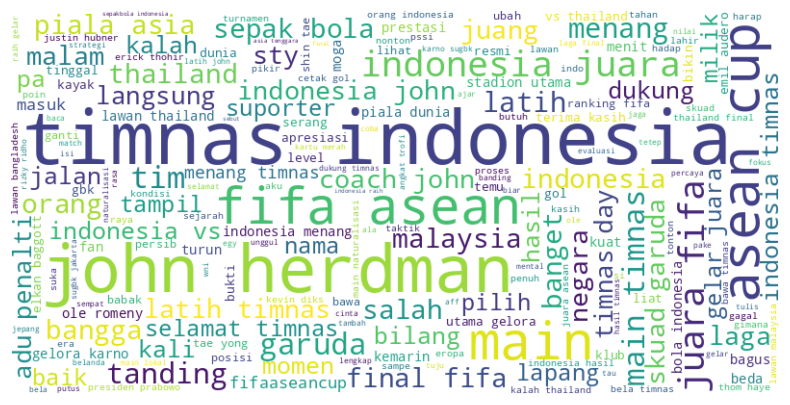

In [107]:
corpus = " ".join(df_bow["tokens_stemmed"].to_list())

# Buat Word Cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    colormap="viridis"
).generate(corpus)

# Tampilkan
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()


In [108]:
wordcloud

pertahankan kata:
pertimbangan

## Word Embeddings (Representasi Berbasis Deep Learning)
Mengubah kata atau teks menjadi vektor padat (dense vectors) yang mampu menangkap makna semantik dan hubungan antar kata (contoh: Word2Vec, GloVe, FastText).
